<a href="https://colab.research.google.com/github/brijesh-rgb/Machine_Learning/blob/main/Machine_Learning/Feature%20Engineering%20part1/Colume_Transformer_%7CDay_28%7C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Colume_Transformer

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv('covid_toy.csv')

In [ ]:
df.shape

(100, 6)

In [ ]:
df.head()

,age,gender,fever,cough,city,has_covid
0,60,Male,103.0,Mild,Kolkata,No
1,27,Male,100.0,Mild,Delhi,Yes
2,42,Male,101.0,Mild,Delhi,No
3,31,Female,98.0,Mild,Kolkata,No
4,65,Female,101.0,Mild,Mumbai,No


<Axes: >

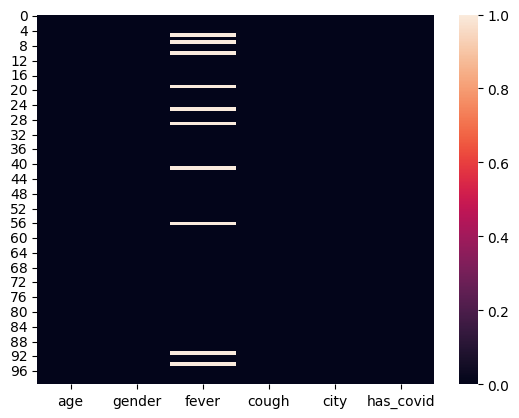

In [ ]:
sns.heatmap(df.isnull())

In [ ]:
print(df.value_counts('city'))
print(df.value_counts('cough'))

city
Kolkata      32
Bangalore    30
Delhi        22
Mumbai       16
Name: count, dtype: int64
cough
Mild      62
Strong    38
Name: count, dtype: int64


# Train_test_split

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(df.drop('has_covid',axis=1),df['has_covid'],test_size=0.2,random_state=42)

In [ ]:
X_train.shape,X_test.shape,Y_train.shape,Y_test.shape

((80, 5), (20, 5), (80,), (20,))

In [ ]:
X_train

,age,gender,fever,cough,city
55,81,Female,101.0,Mild,Mumbai
88,5,Female,100.0,Mild,Kolkata
26,19,Female,100.0,Mild,Kolkata
42,27,Male,100.0,Mild,Delhi
69,73,Female,103.0,Mild,Delhi
...,...,...,...,...,...
60,24,Female,102.0,Strong,Bangalore
71,75,Female,104.0,Strong,Delhi
14,51,Male,104.0,Mild,Bangalore
92,82,Female,102.0,Strong,Kolkata


# 1. Aam Zindagi
* gender , city -> OneHotEncoding
* cough   -> OrdinalEncoding
* has_covid -> LabelEncoding

###  adding simple imputer to fever col


In [ ]:
# adding simple imputer to fever col
si = SimpleImputer()
X_train_fever = si.fit_transform(X_train[['fever']])

# also the test data
X_test_fever = si.fit_transform(X_test[['fever']])

X_train_fever.shape

(80, 1)

In [ ]:
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder
from sklearn.impute import SimpleImputer


### Object of class

In [ ]:
oe = OrdinalEncoder()
ohe = OneHotEncoder()
le = LabelEncoder()


In [ ]:
# OrdinalEncoder
X_train_cough = oe.fit_transform(X_train[['cough']])

# also the test data
X_test_cough = oe.fit_transform(X_test[['cough']])

X_train_cough.shape

(80, 1)

In [ ]:
# OneHotEncoder
X_train_gender_city = ohe.fit_transform(X_train[['gender','city']])

# also the test data
X_test_gender_city = ohe.fit_transform(X_test[['gender','city']])

In [ ]:
# Label Encoder
Y_train = le.fit_transform(Y_train)
Y_test = le.fit_transform(Y_test)

In [ ]:
# Extracting Age
X_train_age = X_train.drop(columns=['gender','fever','cough','city']).values

# also the test data
X_test_age = X_test.drop(columns=['gender','fever','cough','city']).values

X_train_age.shape

(80, 1)

# Merge all to one

In [ ]:
print('Shape of X_train_fever:', X_train_fever.shape)
print('Shape of X_train_gender_city:', X_train_gender_city.shape)
print('Shape of X_train_cough:', X_train_cough.shape)

Shape of X_train_fever: (80, 1)
Shape of X_train_gender_city: (80, 6)
Shape of X_train_cough: (80, 1)


In [ ]:
X_train_transformed = np.concatenate((X_train_age,X_train_fever,X_train_gender_city.toarray(),X_train_cough),axis=1)
# also the test data
X_test_transformed = np.concatenate((X_test_age,X_test_fever,X_test_gender_city.toarray(),X_test_cough),axis=1)

X_train_transformed.shape

(80, 9)

# 2. Mentos Zindagi

In [ ]:
from sklearn.compose import ColumnTransformer